# Laboratory Work #1 — Monte Carlo Policy Evaluation
**Mukhamedali Daniyaruly · Student ID: 23B031269 · CSCI3235 Reinforcement Learning**

Environment: TinyChain (A → B → C → TERMINAL), fixed policy, γ = 0.9, fixed random seed 42.
The notebook runs top to bottom without manual edits.

## Task A — First-visit Monte Carlo (all TODOs implemented)

In [1]:
import random
from collections import defaultdict

import matplotlib.pyplot as plt

GAMMA = 0.9
STATES = ("A", "B", "C")

def generate_episode(rng):
    state = "A"
    episode = []
    while state != "TERMINAL":
        if state == "A":
            next_state, reward = ("B", 0) if rng.random() < 0.8 else ("TERMINAL", 0)
        elif state == "B":
            next_state, reward = ("C", 1) if rng.random() < 0.5 else ("TERMINAL", 1)
        else:
            next_state, reward = "TERMINAL", 3
        episode.append((state, reward, next_state))
        state = next_state
    return episode

def first_visit_mc(num_episodes, gamma=GAMMA, seed=42):
    rng = random.Random(seed)
    returns = defaultdict(list)
    for _ in range(num_episodes):
        episode = generate_episode(rng)
        G = 0.0
        state_returns = []
        for state, reward, next_state in reversed(episode):
            G = reward + gamma * G                 # TODO 1: discounted return, built backwards
            state_returns.append((state, G))       # TODO 2: remember the return from this state
        seen = set()
        for state, G in reversed(state_returns):   # walk forwards in time
            if state in seen:                      # TODO 3: only the first occurrence counts
                continue
            seen.add(state)
            returns[state].append(G)               # TODO 4: store the return for averaging
    # TODO 5: mean return per state (a state never visited gets no estimate)
    return {s: (sum(returns[s]) / len(returns[s]) if returns[s] else None) for s in STATES}

EPISODE_COUNTS = (10, 100, 1000, 10000)
estimates = {}
for n in EPISODE_COUNTS:
    estimates[n] = first_visit_mc(n)
    print(n, {s: round(v, 4) for s, v in estimates[n].items()})

10 {'A': 2.268, 'B': 2.8, 'C': 3.0}
100 {'A': 1.7253, 'B': 2.3667, 'C': 3.0}
1000 {'A': 1.6809, 'B': 2.3001, 'C': 3.0}
10000 {'A': 1.6915, 'B': 2.3376, 'C': 3.0}


## Task B — Exact values from the Bellman expectation equation

For a fixed policy: $V(s) = \sum_{s'} P(s' \mid s)\,[\,R + \gamma V(s')\,]$, with $V(\text{TERMINAL}) = 0$.

**State C** (always goes to TERMINAL with reward 3):
$V(C) = 1.0 \cdot (3 + 0.9 \cdot 0) = \mathbf{3}$

**State B** (reward 1 in both cases; C with prob. 0.5, TERMINAL with prob. 0.5):
$V(B) = 0.5 \cdot (1 + 0.9 \cdot V(C)) + 0.5 \cdot (1 + 0.9 \cdot 0) = 0.5 \cdot 3.7 + 0.5 \cdot 1 = 1.85 + 0.5 = \mathbf{2.35}$

**State A** (reward 0; B with prob. 0.8, TERMINAL with prob. 0.2):
$V(A) = 0.8 \cdot (0 + 0.9 \cdot V(B)) + 0.2 \cdot (0 + 0) = 0.8 \cdot 0.9 \cdot 2.35 = 0.72 \cdot 2.35 = \mathbf{1.692}$

The chain has no loops, so the values are solved backwards: C first, then B, then A.

In [2]:
V_C = 1.0 * (3 + GAMMA * 0)
V_B = 0.5 * (1 + GAMMA * V_C) + 0.5 * (1 + GAMMA * 0)
V_A = 0.8 * (0 + GAMMA * V_B) + 0.2 * (0 + GAMMA * 0)
V_EXACT = {"A": V_A, "B": V_B, "C": V_C}
print({s: round(v, 4) for s, v in V_EXACT.items()})

{'A': 1.692, 'B': 2.35, 'C': 3.0}


## Task C — Absolute error |V_MC(s) − V_exact(s)|

In [3]:
header = f"{'episodes':>9} | {'V_MC(A)':>8} {'V_MC(B)':>8} {'V_MC(C)':>8} | {'err A':>7} {'err B':>7} {'err C':>7}"
print(header)
print("-" * len(header))
for n in EPISODE_COUNTS:
    est = estimates[n]
    vals = " ".join(f"{est[s]:8.4f}" for s in STATES)
    errs = " ".join(f"{abs(est[s] - V_EXACT[s]):7.4f}" for s in STATES)
    print(f"{n:>9} | {vals} | {errs}")
print(f"{'exact':>9} | " + " ".join(f"{V_EXACT[s]:8.4f}" for s in STATES))

 episodes |  V_MC(A)  V_MC(B)  V_MC(C) |   err A   err B   err C
----------------------------------------------------------------
       10 |   2.2680   2.8000   3.0000 |  0.5760  0.4500  0.0000
      100 |   1.7253   2.3667   3.0000 |  0.0333  0.0167  0.0000
     1000 |   1.6809   2.3001   3.0000 |  0.0111  0.0499  0.0000
    10000 |   1.6915   2.3376   3.0000 |  0.0005  0.0124  0.0000
    exact |   1.6920   2.3500   3.0000


**Observation.** V(C) is exact for every episode count: C always gives return 3, so there is no randomness after C.
The errors for A and B shrink as the number of episodes grows (with noise: Monte Carlo error falls roughly like 1/√n, so it does not have to decrease at every single step: here the error for B is 0.017 at 100 episodes but 0.050 at 1,000, and then 0.012 at 10,000).
At 10 episodes, B and C are visited only a few times, so their averages rest on very few returns.

## Task D — Estimates vs. number of episodes

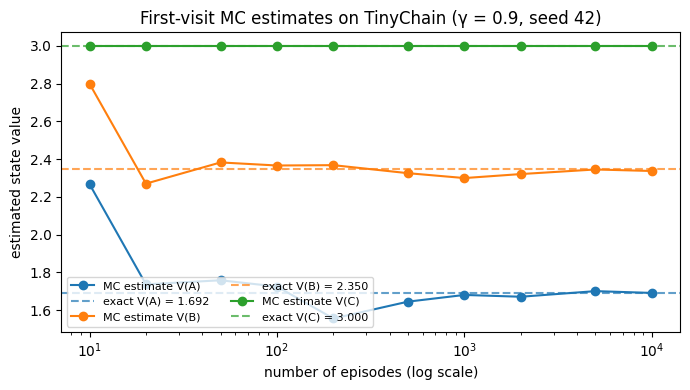

In [4]:
PLOT_COUNTS = [10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000]
curve = {n: first_visit_mc(n) for n in PLOT_COUNTS}

fig, ax = plt.subplots(figsize=(7, 4))
for s, color in zip(STATES, ("tab:blue", "tab:orange", "tab:green")):
    ax.plot(PLOT_COUNTS, [curve[n][s] for n in PLOT_COUNTS], "o-", color=color, label=f"MC estimate V({s})")
    ax.axhline(V_EXACT[s], ls="--", color=color, alpha=0.7, label=f"exact V({s}) = {V_EXACT[s]:.3f}")
ax.set_xscale("log")
ax.set_xlabel("number of episodes (log scale)")
ax.set_ylabel("estimated state value")
ax.set_title("First-visit MC estimates on TinyChain (γ = 0.9, seed 42)")
ax.legend(fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

**Do the estimates stabilize?** Yes. With few episodes (10–100) V(A) and V(B) jump around, because each estimate is an average of only a few noisy returns.
From about 1,000 episodes on, the curves stay close to the dashed exact values, and at 10,000 episodes all three estimates are almost on the exact lines.
This is the law of large numbers: the sample mean of the returns converges to the expected return Vπ(s).
V(C) is flat at 3 from the start because its return is deterministic.

## Task E — Conceptual questions

**1. Why is this Monte Carlo method model-free even though we know the transition probabilities for verification?**
The algorithm never uses the transition probabilities or the reward table; it only averages returns from sampled episodes.
We use the known probabilities only in Task B to check the answer. The same MC code would work if the environment were a black box that we could only sample from.

**2. Why can we calculate G only after completing an episode in this implementation?**
G_t is the discounted sum of *all* rewards from time t to the end of the episode, so it is not known until the episode terminates.
The code therefore computes G backwards over the finished episode (G = r + γG). Monte Carlo does not bootstrap from other estimates, unlike TD methods such as SARSA, which update after every step.

**3. What is the difference between first-visit and every-visit MC?**
First-visit MC uses only the return after the *first* time a state appears in an episode; every-visit MC averages the returns after *every* occurrence of that state.
Both converge to Vπ(s). In TinyChain every state appears at most once per episode (A → B → C, no loops), so the two methods give identical estimates here.

**4. How would a larger discount factor γ change the value of state A?**
Symbolically, V(A) = 0.8γ · (1 + 0.5γ · 3) = 0.8γ + 1.2γ². All rewards from A arrive later and all are non-negative, so a larger γ discounts them less and V(A) increases:
γ = 0.5 gives 0.70, γ = 0.9 gives 1.692, and γ = 1 gives 2.0 (computed below).

In [5]:
for g in (0.5, 0.9, 0.99, 1.0):
    print(f"gamma = {g:<4}  exact V(A) = {0.8 * g + 1.2 * g ** 2:.4f}   MC (10,000 episodes) V(A) = {first_visit_mc(10000, gamma=g)['A']:.4f}")

gamma = 0.5   exact V(A) = 0.7000   MC (10,000 episodes) V(A) = 0.7007
gamma = 0.9   exact V(A) = 1.6920   MC (10,000 episodes) V(A) = 1.6915
gamma = 0.99  exact V(A) = 1.9681   MC (10,000 episodes) V(A) = 1.9671
gamma = 1.0   exact V(A) = 2.0000   MC (10,000 episodes) V(A) = 1.9989


## AI use statement
I used Claude Code (Anthropic) to help write this notebook. I checked the exact values by hand (V(C) = 3, V(B) = 2.35, V(A) = 1.692), confirmed that the Monte Carlo estimates approach them, and can explain every TODO.